# WP2: Artificial Lagrange points

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Library & constant imports

In [ ]:
from constants import *

import numpy as np
import scipy 
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import pickle
import nbimporter
from IPython.display import display

# ── Font sizes for plots (adjustable) ──────────────────────────────────────────
FONTSIZE_SMALL = 16              # Contour labels, small text
FONTSIZE_TICKS = 15              # Tick labels
FONTSIZE_AXIS_LABELS = 30        # Axis point labels
FONTSIZE_XLABEL_YLABEL = 16      # Axis label text
FONTSIZE_LEGEND = 15             # Legend and annotations
FONTSIZE_TITLE = 36              # Main titles

## Task 2.1a 

We now want to equip the spacecraft with a solar sail; this will allow a shift in the location of the Lagrange points. Assume we want to shift both Lagrange points found in Task 1.1a by a certain amount; and we want this shift to occur along the line connecting the Sun and the Lagrange point *in the direction of the Sun*. The amount by which the Lagrange points shall be shifted can be found *in your personal problem specification*.

Compute the required solar-sail performance, i.e., the solar-sail lightness number, to achieve this shift. Assume an ideal performance of the sail

Loading the values from the previous computation:

In [202]:
with open('lagrange_points.pkl', 'rb') as f:
    lagrange_points = pickle.load(f)

L1_earth = lagrange_points['L1_earth']
L2_earth = lagrange_points['L2_earth']
L2_mars  = lagrange_points['L2_mars']

Conversion of the points into the artificial lagrance points by the shift specified.

In [203]:
L2_artificial_earth = L2_earth - shift_L2
L2_artificial_mars  = L2_mars  - shift_L2

Due to the potential being non-dependant on $y$, $\nabla U$ is collinear with the Sun-Earth line. Hence, the expression for calculating the solar sail orientation ($\mathbf{\hat{n}} = \frac{\nabla U}{|\nabla U|}$) trivially yields $\mathbf{\hat{n}} \parallel x$. 
Hence, the equation provided in the slides to calculate the solar-sail lightness number simplifies as it follows:

$$\beta = - \frac{r_1^2}{1 - \mu} \frac{\nabla U \cdot \mathbf{\hat{n}}}{( \mathbf{\hat{r}_1} \cdot \mathbf{\hat{n}})^2} \xRightarrow{\mathbf{\hat{n}} \parallel \mathbf{\hat{r}_1}} \beta = - \frac{1}{1 - \mu} \frac{dU}{dx}$$

So, for the Sun-Earth system it yields:

In [204]:
from wp1 import dUdx_colinear, nablaU

def beta_sail(x, y, MU):
    r1x, r1y = x + MU, y
    r1_sq = r1x**2 + r1y**2
    dUdx, dUdy, _ = nablaU(MU, x, y)
    grad_mag = np.sqrt(dUdx**2 + dUdy**2)
    r1_mag = np.sqrt(r1_sq)
    r1_dot_n = (r1x*dUdx + r1y*dUdy) / (r1_mag * grad_mag) 

    with np.errstate(divide='ignore', invalid='ignore'):
        b = -(r1_sq / (1 - MU)) * grad_mag / r1_dot_n
    return b

beta_earth = beta_sail(L2_artificial_earth, 0, mass_ratio_sun_earth)
print(f"Solar-sail lightness number at artificial Sun-Earth L2: {beta_earth:.5f}")

Solar-sail lightness number at artificial Sun-Earth L2: 0.01008


And for the Sun-Mars system:

In [205]:
beta_mars = beta_sail(L2_artificial_mars, 0, mass_ratio_sun_mars)
print(f"Solar-sail lightness number at artificial Sun-Mars L2: {beta_mars:.5f}")

Solar-sail lightness number at artificial Sun-Mars L2: 0.01163


### Calculating the solar sail lightness area from sources

The solar-sail lightness number $\beta$ is related to the area-to-mass ratio by:

$$\beta = \frac{2 P r^2}{\mu_\odot} \cdot \frac{A}{m} = \frac{2 P_0 r_0^2}{\mu_\odot} \cdot \frac{A}{m}$$

where:
- $P_0$ is the solar radiation pressure at reference distance $r_0=1 \text{AU}$, equal to $4.5 \mu\text{N/m}^2$ as per the course slides
- $\mu_\odot$ is the solar gravitational parameter
- $A/m$ is the area-to-mass ratio of the sail

In [206]:
P_0 = 4.5e-6 # N/m^2
def lightness_number_to_area_per_mass(area, mass):
    return  2* P_0 * (AU*1e3)**2/ (mu_sun*1e9) * (area / mass)

Parameters for certain missions (from [Ancona and Kezerashvili, 2024](https://arxiv.org/pdf/2411.12492); [SunSPOT mission](https://www.sciencedirect.com/science/article/pii/S0273117722003374); [Recent advances in space sailing missions and technology](https://arxiv.org/abs/2411.12492)):

In [207]:
mission = ["Cosmos-1", "NanoSail-D1", "IKAROS", "NanoSail-D2", "LightSail 1", "LightSail 2", "NEA Scout", "GAMA Alpha", "ACS3", "SunSPOT", 'Sunjammer']
year = [2005, 2008, 2010, 2011, 2015, 2019, 2022, 2023, 2024, 2033, 2015]
mass = [100, 4, 315, 4, 5, 5, 14, 12, 16, 1373, 45] # kg
surface_area = [600, 10, 200, 10, 32, 32, 86, 73, 80, 180**2, 1200] # m^2
status = ['F', 'F', 'S', 'S', 'S', 'S', 'F', 'S', 'S', 'P', 'F']  # F: Failed, S: Success, P: Planned

Calculation of the lightness number

In [208]:
beta_values = []
for m, a in zip(mass, surface_area):
    beta = lightness_number_to_area_per_mass(a, m)
    print(f"Mission {mission[len(beta_values)]} ({year[len(beta_values)]}) lightness number: {beta:.5f}")
    beta_values.append(beta)

Mission Cosmos-1 (2005) lightness number: 0.00911
Mission NanoSail-D1 (2008) lightness number: 0.00379
Mission IKAROS (2010) lightness number: 0.00096
Mission NanoSail-D2 (2011) lightness number: 0.00379
Mission LightSail 1 (2015) lightness number: 0.00971
Mission LightSail 2 (2019) lightness number: 0.00971
Mission NEA Scout (2022) lightness number: 0.00932
Mission GAMA Alpha (2023) lightness number: 0.00923
Mission ACS3 (2024) lightness number: 0.00759
Mission SunSPOT (2033) lightness number: 0.03581
Mission Sunjammer (2015) lightness number: 0.04047


Plotting of the lightness number vs the launch year:

Figure saved to figures/solar_sail_lightness_number.pdf


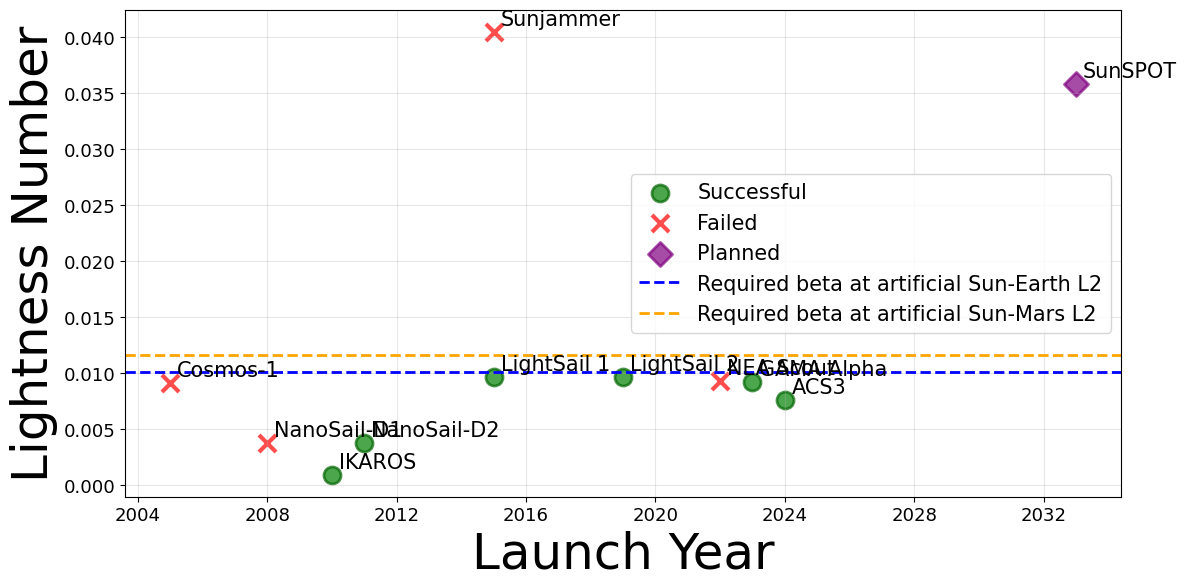

In [209]:
import os

# Create figures directory if it doesn't exist
figures_dir = 'figures'
if not os.path.exists(figures_dir):
    os.makedirs(figures_dir)

plt.figure(figsize=(12, 6))

# Separate missions by status
success_indices = [i for i in range(len(status)) if status[i] == 'S']
fail_indices = [i for i in range(len(status)) if status[i] == 'F']
planned_indices = [i for i in range(len(status)) if status[i] == 'P']

# Plot successful missions with circles
success_years = [year[i] for i in success_indices]
success_betas = [beta_values[i] for i in success_indices]
plt.scatter(success_years, success_betas, s=150, color='green', alpha=0.7, marker='o', label='Successful', edgecolors='darkgreen', linewidth=2)

# Plot failed missions with X markers
fail_years = [year[i] for i in fail_indices]
fail_betas = [beta_values[i] for i in fail_indices]
plt.scatter(fail_years, fail_betas, s=150, color='red', alpha=0.7, marker='x', linewidth=3, label='Failed')

# Plot planned missions with diamond markers
planned_years = [year[i] for i in planned_indices]
planned_betas = [beta_values[i] for i in planned_indices]
plt.scatter(planned_years, planned_betas, s=150, color='purple', alpha=0.7, marker='D', linewidth=2, label='Planned')

# Add mission name labels to each point
for i, mission_name in enumerate(mission):
    plt.annotate(mission_name, (year[i], beta_values[i]), 
                xytext=(5, 5), textcoords='offset points', fontsize=FONTSIZE_LEGEND)

# Add horizontal lines for artificial Lagrange points
plt.axhline(y=beta_earth, color='blue', linestyle='--', linewidth=2, label=f'Required beta at artificial Sun-Earth L2')
plt.axhline(y=beta_mars, color='orange', linestyle='--', linewidth=2, label=f'Required beta at artificial Sun-Mars L2')

plt.xlabel('Launch Year', fontsize=FONTSIZE_TITLE)
plt.ylabel('Lightness Number', fontsize=FONTSIZE_TITLE)
# plt.title('Solar Sail Lightness Number vs Launch Year', fontsize=FONTSIZE_TITLE)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.xticks(fontsize=FONTSIZE_TICKS)
plt.yticks(fontsize=FONTSIZE_TICKS)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=FONTSIZE_LEGEND, loc='best')
plt.tight_layout()

# Save figure as PDF
pdf_path = os.path.join(figures_dir, 'solar_sail_lightness_number.pdf')
plt.savefig(pdf_path, format='pdf', dpi=300, bbox_inches='tight')
print(f"Figure saved to {pdf_path}")

plt.show()

## Task 2.1b 

Schematic for the acceleration vectors in the solar-sail augmented CR3BP

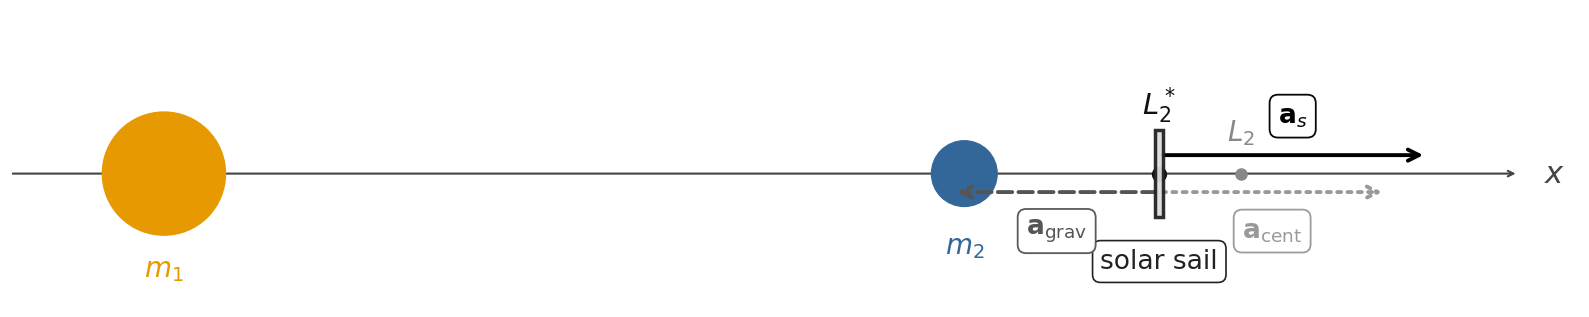

In [210]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

# ── greyscale-safe palette (distinct in both colour and lightness) ─────────────
# a_s:    solid black        (greyscale: ~0.0)
# a_grav: dark grey          (greyscale: ~0.35)
# a_cent: medium grey        (greyscale: ~0.55)  + dashed line to distinguish
# sail:   light grey fill    (greyscale: ~0.85)
C_AS    = '#000000'   # black
C_GRAV  = '#555555'   # dark grey
C_CENT  = '#999999'   # medium grey
C_SAIL_E = '#222222'  # sail edge
C_SAIL_F = '#DDDDDD'  # sail fill
C_SUN   = '#E69900'   # amber  (prints mid-grey)
C_PLAN  = '#336699'   # steel blue (prints dark-grey)
C_AXIS  = '#444444'
C_L2N   = '#888888'
C_L2A   = '#111111'

FS      = 20   # base font size
FS_LBL  = 19   # vector label font size
LW_VEC  = 2.8  # arrow line width
MS_VEC  = 20   # arrowhead scale

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_aspect('equal')
ax.axis('off')

# ── positions ─────────────────────────────────────────────────────────────────
x_sun    = -6.0
x_planet =  1.8
x_L2     =  4.5
x_L2art  =  3.7
y0       =  0.0

# ── x-axis ────────────────────────────────────────────────────────────────────
ax.annotate('', xy=(7.2, 0), xytext=(-7.5, 0),
            arrowprops=dict(arrowstyle='->', color=C_AXIS, lw=1.5))
ax.text(7.45, 0, r'$x$', fontsize=FS+2, va='center', color=C_AXIS)

# ── natural L2 ────────────────────────────────────────────────────────────────
ax.plot(x_L2, y0, 'o', ms=8, color=C_L2N, zorder=3)
ax.text(x_L2, 0.32, r'$L_2$', ha='center', fontsize=FS, color=C_L2N, zorder=3)

# ── artificial L2 ─────────────────────────────────────────────────────────────
ax.plot(x_L2art, y0, 'o', ms=10, color=C_L2A, zorder=30)
ax.text(x_L2art, 0.58, r'$L_2^*$', ha='center', fontsize=FS+1,
        color=C_L2A, fontweight='bold', zorder=30)

# ── solar sail ────────────────────────────────────────────────────────────────
sail_w, sail_h = 0.08, 0.85
ax.add_patch(mpatches.FancyBboxPatch(
    (x_L2art - sail_w/2, y0 - sail_h/2), sail_w, sail_h,
    boxstyle='square,pad=0', linewidth=2.5,
    edgecolor=C_SAIL_E, facecolor=C_SAIL_F, zorder=30, alpha=0.95))
ax.text(x_L2art, y0 - sail_h/2 - 0.50, 'solar sail',
        ha='center', fontsize=FS-1, color=C_SAIL_E,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=C_SAIL_E, lw=1.2))

# ── bodies ────────────────────────────────────────────────────────────────────
ax.add_patch(plt.Circle((x_sun,    y0), 0.60, color=C_SUN,  zorder=20))
ax.add_patch(plt.Circle((x_planet, y0), 0.32, color=C_PLAN, zorder=20))
ax.text(x_sun,    -1.00, r'$m_1$',    ha='center', fontsize=FS, color=C_SUN)
ax.text(x_planet, -0.78, r'$m_2$', ha='center', fontsize=FS, color=C_PLAN)

# ── helper: FancyArrowPatch + label box ───────────────────────────────────────
def vec(ax, x0, y0, dx, dy, color, label, lbl_offset=(0.0, 0.36),
        lw=LW_VEC, linestyle='solid'):
    arrow = FancyArrowPatch(
        posA=(x0, y0), posB=(x0+dx, y0+dy),
        arrowstyle='->', color=color, lw=lw,
        mutation_scale=MS_VEC, zorder=25,
        linestyle=linestyle)
    ax.add_patch(arrow)
    lx = x0 + dx/2 + lbl_offset[0]
    ly = y0 + dy/2 + lbl_offset[1]
    ax.text(lx, ly, label, ha='center', va='center',
            fontsize=FS_LBL, color=color, zorder=26,
            bbox=dict(boxstyle='round,pad=0.32', fc='white', ec=color,
                      alpha=0.97, lw=1.3))

# a_s: solid black, top lane, rightward (+x)
vec(ax, x_L2art, y0 + 0.18,  2.6, 0.0, C_AS,
    r'$\mathbf{a}_s$', lbl_offset=(0.0, 0.38))

# a_grav: dark grey, dashed, toward Sun (-x)
vec(ax, x_L2art, y0 - 0.18, -2.0, 0.0, C_GRAV,
    r'$\mathbf{a}_{\mathrm{grav}}$', lbl_offset=(0.0, -0.38),
    linestyle='dashed')

# a_cent: medium grey, dotted, rightward (+x)
vec(ax, x_L2art, y0 - 0.18,  2.2, 0.0, C_CENT,
    r'$\mathbf{a}_{\mathrm{cent}}$', lbl_offset=(0.0, -0.38),
    linestyle='dotted')

ax.set_xlim(-7.5, 7.8)
ax.set_ylim(-1.3, 1.6)

plt.tight_layout()
plt.savefig('figures/sail_L2_schematic.pdf', bbox_inches='tight', dpi=200)

display(fig)
plt.close()

## Task 2.2

Replication of the plots shown in [Solar Sail Parking in Restricted Three-Body Systems](https://sci-hub.st/10.2514/3.21211). More speficially Fig 3 b).

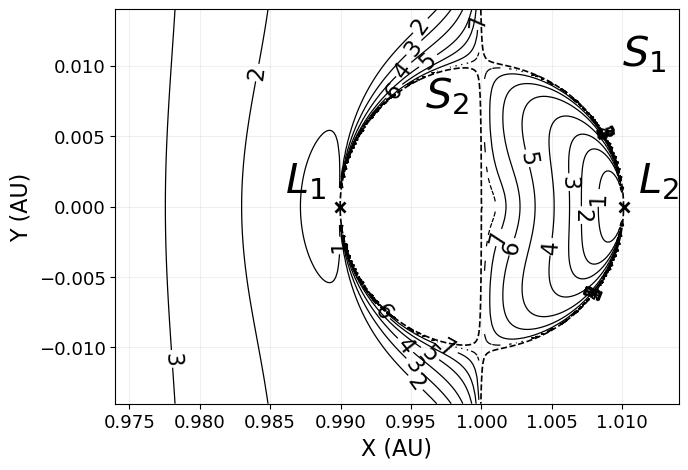

In [211]:
def S_boundary(x, y):
    dUdx_, dUdy_, _ = nablaU(mass_ratio_sun_earth, x, y)
    return (x + mass_ratio_sun_earth) * dUdx_ + y * dUdy_

# Grid
N = 300
x_vec = np.linspace(0.974, 1.014, N)
y_vec = np.linspace(-0.014, 0.014, N)
XX, YY = np.meshgrid(x_vec, y_vec)

# beta_sail on the full grid (with the corrected minus sign)
B = np.array([[beta_sail(xv, yv, mass_ratio_sun_earth) for xv in x_vec] for yv in y_vec])
S = S_boundary(XX, YY)

# Mask bodies and forbidden regions
r2 = np.sqrt((XX - (1 - mass_ratio_sun_earth))**2 + YY**2)
# B[r2 < 0.004] = np.nan
# B[B < 0] = np.nan          # only positive beta (sail pointing sunward)
B[B > 3.5] = np.nan

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))

# Numbered contour levels matching the paper
levels = [0.02, 0.04, 0.06, 0.1, 0.2, 0.4, 1.0, 3.0]
cs = ax.contour(x_vec, y_vec, B, levels=levels,
                colors='k', linewidths=0.9)

# Label contours with the paper numbering (1–8)
fmt = {lv: str(i+1) for i, lv in enumerate(levels)}
ax.clabel(cs, fmt=fmt, fontsize=FONTSIZE_SMALL, inline=True)

# S boundary (dashed)
ax.contour(XX, YY, S, levels=[0], colors='k',
           linewidths=1.2, linestyles='dashed')

# Lagrange points
ax.plot(L1_earth, 0, 'kx', ms=7, mew=2, zorder=5)
ax.plot(L2_earth, 0, 'kx', ms=7, mew=2, zorder=5)
ax.text(L1_earth - 0.001, 0.001, r'$L_1$', fontsize=FONTSIZE_AXIS_LABELS, ha='right')
ax.text(L2_earth + 0.001, 0.001, r'$L_2$', fontsize=FONTSIZE_AXIS_LABELS, ha='left')

# S1/S2 region labels
ax.text(1.01, 0.01, r'$S_1$', fontsize=FONTSIZE_AXIS_LABELS)
ax.text(0.996, 0.007, r'$S_2$', fontsize=FONTSIZE_AXIS_LABELS)

ax.set_xlabel('X (AU)', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel('Y (AU)', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.tick_params(axis='both', which='major', labelsize=FONTSIZE_TICKS)
ax.set_xlim(0.974, 1.014)
ax.set_ylim(-0.014, 0.014)
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('figures/McInnes_fig3b_replication.pdf', dpi=200, bbox_inches='tight')
plt.show()

Comparison against [Sunjammer paper](https://arc.aiaa.org/doi/10.2514/6.2014-4127). That paper uses a value of $\beta = 0.0363$. Goal is to achieve the same artificial L1 point: $x = 0.983867$

In [212]:
L1_shifted = 0.983867 
beta_target = 0.0363

L1_earth = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_earth,))
L2_earth = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_earth,))

L2_sunjammer = scipy.optimize.brentq(
    lambda x: abs(beta_sail(x, 0, mass_ratio_sun_earth)) - beta_target,
    L2_earth - 0.1, L2_earth - 1e-4)
L1_sunjammer = scipy.optimize.brentq(
    lambda x: abs(beta_sail(x, 0, mass_ratio_sun_earth)) - beta_target,
    L1_earth - 0.1, L1_earth - 1e-4)

print(f"L2* x = {L2_sunjammer:.8f}")
print(f"L1* x = {L1_sunjammer:.8f}")
print(f"Error in L1* = {L1_sunjammer - L1_shifted:.8e}")

L2* x = 1.00728597
L1* x = 0.98385550
Error in L1* = -1.15003197e-05


## Task 2.3

Using a mass of 100 kg, the side-length is calculated as follows:

$$A = \frac{\mu_\odot}{2 P r^2} \cdot m \beta \Rightarrow L = \sqrt{\frac{\mu_\odot}{2 P_0 r_0^2} \cdot m \beta}$$

In [213]:
mass_sc = 100 # kg (problem information)
side_length_earth = ( mu_sun*1e9*mass_sc*beta_earth / (2*P_0*(AU*1e3)**2) )**0.5
side_length_mars  = ( mu_sun*1e9*mass_sc*beta_mars  / (2*P_0*(AU*1e3)**2) )**0.5

print(f"Required sail side length at Sun-Earth L2*: {side_length_earth:.3f} m")
print(f"Required sail side length at Sun-Mars L2*: {side_length_mars:.3f} m")

Required sail side length at Sun-Earth L2*: 25.772 m
Required sail side length at Sun-Mars L2*: 27.676 m


## Task 2.4

The problem statement says to increase the shift until it is twice the one stated in the problem specification. 

In [214]:
shift_array = np.linspace(shift_L2, 2*shift_L2, 1000) # the one for the assignment

With that we iterate over the solar sail lightness number, $\beta$. First for the Earth-Sun system:

In [215]:
beta_array_earth = np.empty_like(shift_array)
xi_earth_array = np.empty_like(shift_array)
for i, shift in enumerate(shift_array):
    xi_earth_array[i] = L2_earth - shift
    beta_array_earth[i] = beta_sail(xi_earth_array[i], 0, mass_ratio_sun_earth)

And then for the Mars-Sun system:

In [216]:
beta_array_mars = np.empty_like(shift_array)
xi_mars_array = np.empty_like(shift_array)
for i, shift in enumerate(shift_array):
    xi_mars_array[i] = L2_mars - shift
    beta_array_mars[i] = beta_sail(xi_mars_array[i], 0, mass_ratio_sun_mars)

And plot the results of the lightness number vs the shift. 

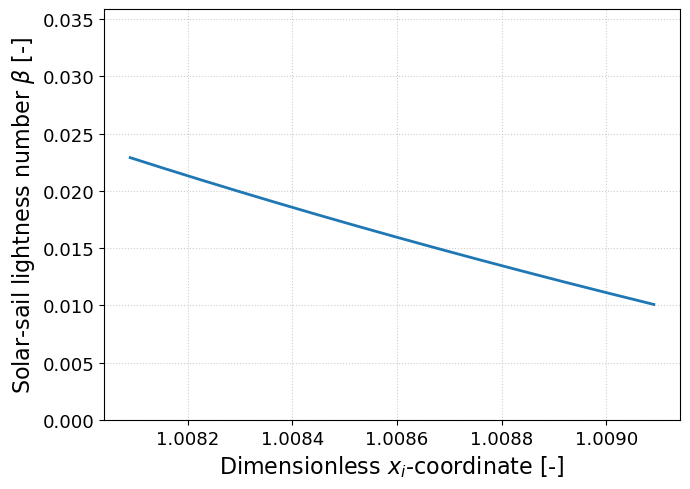

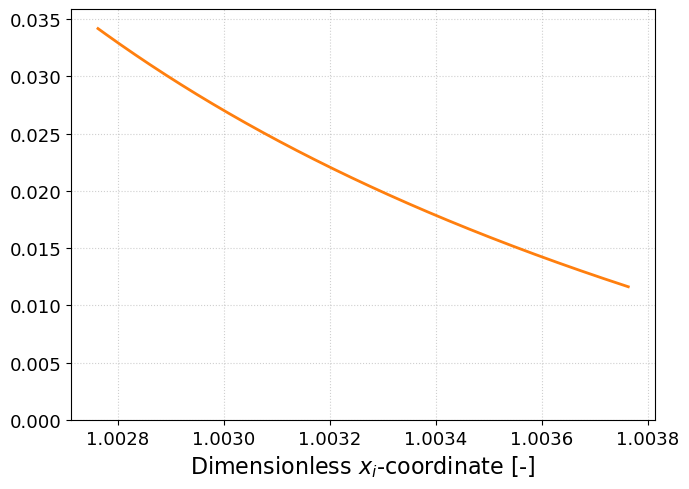

In [217]:
# Create figures directory if it doesn't exist
os.makedirs('figures', exist_ok=True)

# Calculate common y-axis range for both plots
y_min = 0# min(np.nanmin(beta_array_earth), np.nanmin(beta_array_mars))
y_max = max(np.nanmax(beta_array_earth), np.nanmax(beta_array_mars))
y_margin = (y_max - y_min) * 0.05  # 5% margin
y_lim = (y_min, y_max + y_margin)

# 1. Sun-Earth Sensitivity Figure
plt.figure(figsize=(7, 5))
plt.plot(xi_earth_array, beta_array_earth, color='tab:blue', label='Sun-Earth $L_2$', linewidth=2)
plt.xlabel('Dimensionless $x_i$-coordinate [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
plt.ylabel('Solar-sail lightness number $\\beta$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.title('Sun-Earth $L_2$ Sensitivity Analysis', fontsize=FONTSIZE_TITLE)
plt.grid(True, linestyle=':', alpha=0.6)
# plt.legend(fontsize=FONTSIZE_LEGEND)
plt.xticks(fontsize=FONTSIZE_TICKS)
plt.yticks(fontsize=FONTSIZE_TICKS)
plt.ticklabel_format(useOffset=False)
plt.ylim(y_lim)
plt.tight_layout()
plt.savefig('figures/sensitivity_earth.pdf', format='pdf')
plt.show()

# 2. Sun-Mars Sensitivity Figure
plt.figure(figsize=(7, 5))
plt.plot(xi_mars_array, beta_array_mars, color='tab:orange', label='Sun-Mars $L_2$', linewidth=2)
plt.xlabel('Dimensionless $x_i$-coordinate [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.ylabel('Solar-sail lightness number $\\beta$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.title('Sun-Mars $L_2$ Sensitivity Analysis', fontsize=FONTSIZE_TITLE)
plt.grid(True, linestyle=':', alpha=0.6)
# plt.legend(fontsize=FONTSIZE_LEGEND)
plt.xticks(fontsize=FONTSIZE_TICKS)
plt.yticks(fontsize=FONTSIZE_TICKS)
plt.ticklabel_format(useOffset=False)
plt.ylim(y_lim)
plt.tight_layout()
plt.savefig('figures/sensitivity_mars.pdf', format='pdf')
plt.show()

### Discussion of the results

$$\beta = - \frac{1}{1-\mu} \frac{dU}{dx}$$

$$\frac{dU}{dx} = -\frac{(1-\mu)(x+\mu)}{r_1^3} - \frac{\mu(x-(1-\mu))}{r_2^3} + x, x=x_{L2} - \delta, $$
where $\delta$ is the shift in the Lagrange point.

Then, a first-order Taylor expansion of the expression ia taken around $x_{L2}$ (valid only for $\delta \ll r_2$). Through some derivation, we can arrive at 
$$\boxed{\beta(\delta) = \frac{\delta}{1-\mu}\left(\frac{2(1-\mu)}{r_1^3} + \frac{2\mu}{r_2^3} + 1\right)}$$

In [218]:
def beta_analytical(delta, x_L2, mu):
    """
    Linear Taylor approximation: beta ≈ delta / (1-mu) * U_xx
    with r1, r2 evaluated at the shifted position x = x_L2 - delta.
    """
    # x = x_L2 - delta
    r1 = abs(x_L2 + mu)
    r2 = abs(x_L2 - (1 - mu))
    U_xx = 2*(1 - mu)/r1**3 + 2*mu/r2**3 + 1
    return delta * U_xx / (1 - mu)

Building the approximated analytical $\beta$:

In [219]:
shift_array_analytical = np.linspace(0, shift_L2, 1000) # testing

beta_analytical_earth = np.empty_like(shift_array_analytical)
beta_analytical_mars = np.empty_like(shift_array_analytical)
xi_earth_array_analytical = np.empty_like(shift_array_analytical)
xi_mars_array_analytical = np.empty_like(shift_array_analytical)
beta_earth_array_comparison = np.empty_like(shift_array_analytical)
beta_mars_array_comparison = np.empty_like(shift_array_analytical)

for i, shift in enumerate(shift_array_analytical):
    # earth
    xi_earth_array_analytical[i] = L2_earth - shift
    beta_earth_array_comparison[i] = beta_sail(xi_earth_array_analytical[i], 0, mass_ratio_sun_earth)
    beta_analytical_earth[i] = beta_analytical(shift, L2_earth, mass_ratio_sun_earth)

    # mars
    xi_mars_array_analytical[i] = L2_mars - shift
    beta_mars_array_comparison[i] = beta_sail(xi_mars_array_analytical[i], 0, mass_ratio_sun_mars)
    beta_analytical_mars[i] = beta_analytical(shift, L2_mars, mass_ratio_sun_mars)

And plotting the results:

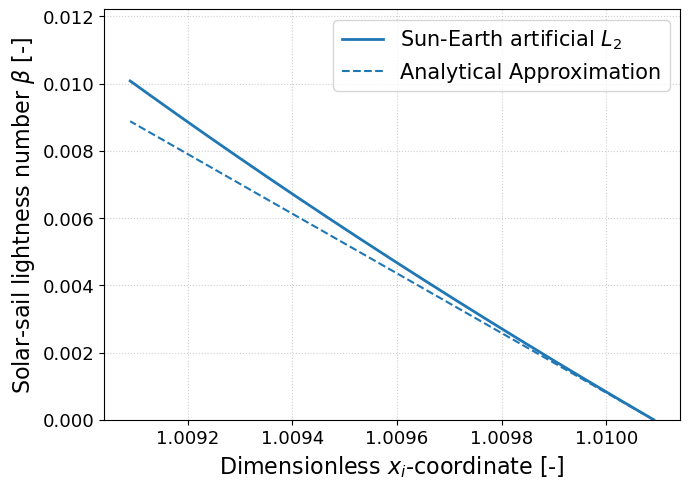

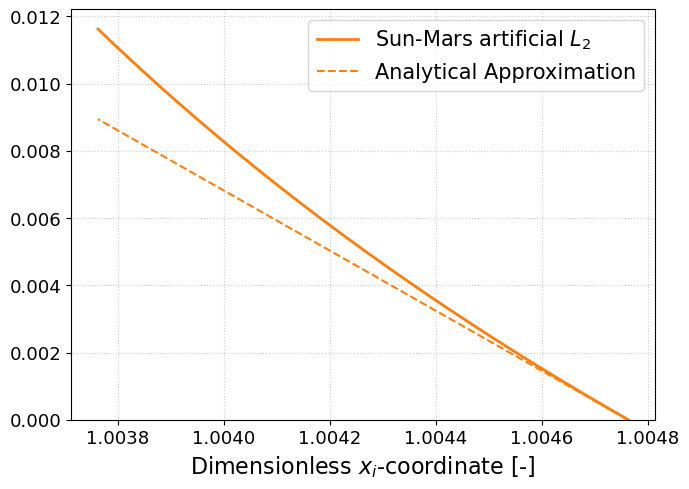

In [220]:
y_min = 0# min(np.nanmin(beta_array_earth), np.nanmin(beta_array_mars))
y_max = max(np.nanmax(beta_earth_array_comparison), np.nanmax(beta_mars_array_comparison))
y_margin = (y_max - y_min) * 0.05  # 5% margin
y_lim = (y_min, y_max + y_margin)

# 1. Sun-Earth Sensitivity Figure
plt.figure(figsize=(7, 5))
plt.plot(xi_earth_array_analytical, beta_earth_array_comparison, color='tab:blue', label='Sun-Earth artificial $L_2$', linewidth=2)
plt.plot(xi_earth_array_analytical, beta_analytical_earth, color='tab:blue', label='Analytical Approximation', linestyle='--')
plt.xlabel('Dimensionless $x_i$-coordinate [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
plt.ylabel('Solar-sail lightness number $\\beta$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.title('Sun-Earth $L_2$ Sensitivity Analysis', fontsize=FONTSIZE_TITLE)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=FONTSIZE_LEGEND)
plt.xticks(fontsize=FONTSIZE_TICKS)
plt.yticks(fontsize=FONTSIZE_TICKS)
plt.ticklabel_format(useOffset=False)
plt.ylim(y_lim)
plt.tight_layout()
plt.savefig('figures/sensitivity_earth_comparison.pdf', format='pdf')
plt.show()

# 2. Sun-Mars Sensitivity Figure
plt.figure(figsize=(7, 5))
plt.plot(xi_mars_array_analytical, beta_mars_array_comparison, color='tab:orange', label='Sun-Mars artificial $L_2$', linewidth=2)
plt.plot(xi_mars_array_analytical, beta_analytical_mars, color='tab:orange', label='Analytical Approximation', linestyle='--')
plt.xlabel('Dimensionless $x_i$-coordinate [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.ylabel('Solar-sail lightness number $\\beta$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# plt.title('Sun-Mars $L_2$ Sensitivity Analysis', fontsize=FONTSIZE_TITLE)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=FONTSIZE_LEGEND)
plt.xticks(fontsize=FONTSIZE_TICKS)
plt.yticks(fontsize=FONTSIZE_TICKS)
plt.ticklabel_format(useOffset=False)
plt.ylim(y_lim)
plt.tight_layout()
plt.savefig('figures/sensitivity_mars_comparison.pdf', format='pdf')
plt.show()

Orders of magnitude analysis of the terms in the potential gradient derivative (Earth case):

In [221]:
r1 = abs(L2_earth + mass_ratio_sun_earth)
r2 = abs(L2_earth - (1 - mass_ratio_sun_earth))

sun_term = 2*(1 - mass_ratio_sun_earth)/r1**3
earth_term = 2*mass_ratio_sun_earth/r2**3
centrifugal_term = 1

print(f"Sun term: {sun_term:.3f}")
print(f"Earth term: {earth_term:.3f}")
print(f"Centrifugal term: {centrifugal_term:.3f}")

Sun term: 1.941
Earth term: 5.940
Centrifugal term: 1.000


Mars case:

In [222]:
r1_mars = abs(L2_mars + mass_ratio_sun_mars)
r2_mars = abs(L2_mars - (1 - mass_ratio_sun_mars))

sun_term_mars = 2*(1 - mass_ratio_sun_mars)/r1_mars**3
mars_term = 2*mass_ratio_sun_mars/r2_mars**3
centrifugal_term_mars = 1

print(f"Sun term (Mars): {sun_term_mars:.3f}")
print(f"Mars term: {mars_term:.3f}")
print(f"Centrifugal term (Mars): {centrifugal_term_mars:.3f}")

Sun term (Mars): 1.972
Mars term: 5.972
Centrifugal term (Mars): 1.000


In the artificial lagrange point (Earth):

In [223]:
r1_earth_artificial = abs(L2_artificial_earth + mass_ratio_sun_earth)
r2_earth_artificial = abs(L2_artificial_earth - (1 - mass_ratio_sun_earth))

sun_term_artificial = 2*(1 - mass_ratio_sun_earth)/r1_earth_artificial**3
earth_term_artificial = 2*mass_ratio_sun_earth/r2_earth_artificial**3
centrifugal_term_artificial = 1

print(f"Sun term: {sun_term_artificial:.3f}")
print(f"Earth term: {earth_term_artificial:.3f}")
print(f"Centrifugal term: {centrifugal_term_artificial:.3f}")

Sun term: 1.946
Earth term: 8.123
Centrifugal term: 1.000


Same for Mars:

In [224]:
r1_mars_artificial = abs(L2_artificial_mars + mass_ratio_sun_mars)
r2_mars_artificial = abs(L2_artificial_mars - (1 - mass_ratio_sun_mars))

sun_term_artificial = 2*(1 - mass_ratio_sun_mars)/r1_mars_artificial**3
mars_term_artificial = 2*mass_ratio_sun_mars/r2_mars_artificial**3
centrifugal_term_artificial = 1

print(f"Sun term: {sun_term_artificial:.3f}")
print(f"Mars term: {mars_term_artificial:.3f}")
print(f"Centrifugal term: {centrifugal_term_artificial:.3f}")

Sun term: 1.978
Mars term: 12.109
Centrifugal term: 1.000


**Summary**:

In [225]:
print("For the classical L2")
print("\nEARTH")
print(f"Sun term: {sun_term:.3f}")
print(f"Earth term: {earth_term:.3f}")
print(f"Centrifugal term: {centrifugal_term:.3f}")
print("\nMARS")
print(f"Sun term: {sun_term_mars:.3f}")
print(f"Mars term: {mars_term:.3f}")
print(f"Centrifugal term: {centrifugal_term_mars:.3f}")
print("\nFor the artificial L2")
print("\nEARTH")
print(f"Sun term: {sun_term_artificial:.3f}")
print(f"Earth term: {earth_term_artificial:.3f}")
print(f"Centrifugal term: {centrifugal_term_artificial:.3f}")
print("\nMARS")
print(f"Sun term: {sun_term_artificial:.3f}")
print(f"Mars term: {mars_term_artificial:.3f}")
print(f"Centrifugal term: {centrifugal_term_artificial:.3f}")

For the classical L2

EARTH
Sun term: 1.941
Earth term: 5.940
Centrifugal term: 1.000

MARS
Sun term: 1.972
Mars term: 5.972
Centrifugal term: 1.000

For the artificial L2

EARTH
Sun term: 1.978
Earth term: 8.123
Centrifugal term: 1.000

MARS
Sun term: 1.978
Mars term: 12.109
Centrifugal term: 1.000
